# E-commerce Customer Analytics: SQL, Cohorts, Customer-Value Prediction and Market Basket

**Business context:** A UK online gift retailer (mostly wholesale customers) sold ~GBP 9.8 M between Dec 2010 and 9 Dec 2011. Marketing wants to know
*who the valuable customers are, whether they stay, who will spend next quarter, and what is bought together.*

**Data:** the real **UCI Online Retail** transactions (541,909 lines, Dec 2010 - Dec 2011; public dataset). It is genuinely messy, so a large part of the work is
cleaning decisions that are documented and defensible.

| Part | Technique |
|---|---|
| 1 | Cleaning pipeline with an audit log (`src/build_db.py`), data loaded into **SQLite** |
| 2-6 | **11 SQL queries** (window functions, CTEs, cohorts, gaps-and-islands) on revenue, products, customers, RFM, returns |
| 7 | **Out-of-time** customer-value model: train on earlier months, test on later months, compared with simple baselines |
| 8 | **Market-basket rules** mined on early data and re-checked on later data |
| 9 | Star-schema export for a **Power BI** dashboard (`/powerbi`) |

All SQL lives in [`/sql`](../sql) as separate files; Python only runs queries, models and draws charts.

In [1]:
import sqlite3, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display
from scipy import sparse, stats
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
con = sqlite3.connect("../data/ecommerce.db"); IMG = "../images/"
def run(name): return pd.read_sql(open(f"../sql/{name}.sql").read(), con)
gbp_k = lambda x, _: f"£{x/1e3:,.0f}k"
mi = lambda ym: int(ym[:4]) * 12 + int(ym[5:7])

## 1. Data audit and cleaning decisions

In [2]:
display(pd.read_sql("SELECT step, rows_removed, rows_remaining, note FROM cleaning_log", con))
g = pd.read_sql("SELECT COUNT(*) AS lines, SUM(customer_id IS NULL) AS guest_lines, SUM(CASE WHEN customer_id IS NULL THEN revenue END) AS guest_rev, SUM(revenue) AS rev FROM transactions", con).iloc[0]
print(f"Lines without a customer ID ('guest' checkouts): {g.guest_lines/g.lines:.1%} of lines, {g.guest_rev/g.rev:.1%} of net revenue")

,step,rows_removed,rows_remaining,note
0,raw file,0,541909,"541,909 transaction lines, 8 columns"
1,exact duplicate rows,5268,536641,identical lines (likely double-scanned); kept ...
2,non-product stock codes,2989,533652,"postage, manual adjustments, fees, discounts, ..."
3,unit price <= 0,2480,531172,"free items / stock adjustments, would distort ..."
4,negative quantity that is not a cancellation,0,531172,"stock write-offs, not customer behaviour"
5,cancellation with positive quantity,0,531172,inconsistent rows
6,flag: sales lines later fully reversed,0,531172,"2,575 lines (GBP 397,603) matched to a cancell..."


Lines without a customer ID ('guest' checkouts): 24.8% of lines, 15.4% of net revenue


**Decisions (each one is a judgement call an interviewer may challenge):**
* **Exact duplicates removed** - identical lines are most likely double scans. Kept the first.
* **Non-product codes removed** (postage, fees, manual adjustments, samples, vouchers): they are not demand for products.
* **Zero/negative prices removed** - free items and stock adjustments.
* **Cancellations are kept** (invoice numbers starting with `C`) and counted as *negative revenue*. Dropping them would overstate sales; keeping them lets returns net out correctly.
* **Guest checkouts** (no customer ID) stay in company-level KPIs but are excluded from every customer-level analysis, because they cannot be linked to a person.
* Sales lines later reversed by an identical cancellation are **flagged, not deleted** (column `is_reversed`).

## 2. Revenue trend and seasonality
`sql/01_monthly_kpis.sql` - CTE, conditional aggregation and `LAG()` for month-over-month change.

,month,gross_sales,returns_value,net_revenue,orders,active_customers,avg_order_value,return_rate_pct,net_mom_pct
0,2010-12,775572.0,-17548.0,758024.0,1550,884,500.4,2.3,NaN
1,2011-01,670362.0,-91525.0,578837.0,1081,739,620.1,13.7,-23.6
2,2011-02,507783.0,-8336.0,499448.0,1093,757,464.6,1.6,-13.7
3,2011-03,689708.0,-10504.0,679204.0,1440,973,479.0,1.5,36.0
4,2011-04,515355.0,-33316.0,482039.0,1235,853,417.3,6.5,-29.0
5,2011-05,739914.0,-8948.0,730966.0,1668,1054,443.6,1.2,51.6
6,2011-06,737559.0,-13714.0,723845.0,1525,990,483.6,1.9,-1.0
7,2011-07,688145.0,-11407.0,676738.0,1452,946,473.9,1.7,-6.5
8,2011-08,724197.0,-22927.0,701270.0,1339,933,540.8,3.2,3.6
9,2011-09,1028314.0,-16981.0,1011333.0,1818,1259,565.6,1.7,44.2


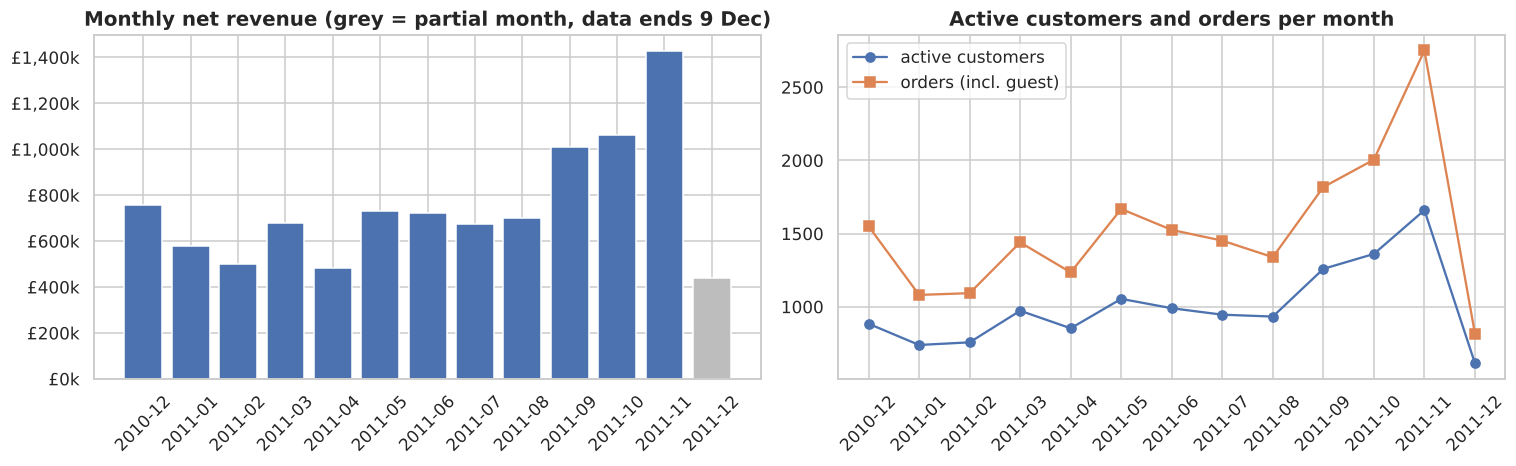

Sep-Nov 2011 = 38% of the 12 full months' net revenue (3 of 12 months) -> strong pre-Christmas season


In [3]:
kpi = run("01_monthly_kpis"); display(kpi)
full = kpi[kpi.month != "2011-12"]
q4 = full[full.month.isin(["2011-09", "2011-10", "2011-11"])].net_revenue.sum() / full.net_revenue.sum()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
ax[0].bar(kpi.month, kpi.net_revenue, color=["#bdbdbd" if m == "2011-12" else "#4c72b0" for m in kpi.month]); ax[0].yaxis.set_major_formatter(gbp_k)
ax[0].set_title("Monthly net revenue (grey = partial month, data ends 9 Dec)"); ax[0].tick_params(axis="x", rotation=45)
ax[1].plot(kpi.month, kpi.active_customers, marker="o", label="active customers"); ax[1].plot(kpi.month, kpi.orders, marker="s", label="orders (incl. guest)")
ax[1].set_title("Active customers and orders per month"); ax[1].legend(); ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(IMG + "01_monthly_trend.png"); plt.show()
print(f"Sep-Nov 2011 = {q4:.0%} of the 12 full months' net revenue (3 of 12 months) -> strong pre-Christmas season")

**Careful with the two odd spikes in `return_rate_pct` (Jan-2011 and Dec-2011).** They are not a quality problem; let's look at the raw lines:

In [4]:
display(pd.read_sql("""SELECT invoice_no, invoice_ts, customer_id, stock_code, quantity, unit_price, ROUND(revenue) AS revenue
                       FROM transactions WHERE invoice_no IN ('541431','C541433','581483','C581484') ORDER BY invoice_ts""", con))

,invoice_no,invoice_ts,customer_id,stock_code,quantity,unit_price,revenue
0,541431,2011-01-18 10:01:00,12346,23166,74215,1.04,77184.0
1,C541433,2011-01-18 10:17:00,12346,23166,-74215,1.04,-77184.0
2,581483,2011-12-09 09:15:00,16446,23843,80995,2.08,168470.0
3,C581484,2011-12-09 09:27:00,16446,23843,-80995,2.08,-168470.0


Two wholesale orders of **GBP 77k** and **GBP 168k** were entered and reversed within minutes (typing mistakes). Net revenue is unaffected because the cancellation nets them out,
but *gross sales* and *return rate* for those two months are inflated. This is exactly why cancellations are kept as negative rows instead of being dropped (which would leave the mistaken orders in as real sales).

## 3. Products and countries
`sql/02_product_pareto.sql`, `sql/03_country_mix.sql`

,rnk,stock_code,description,units_sold,net_revenue,share_pct,cumulative_share_pct
0,1,22423,REGENCY CAKESTAND 3 TIER,13851,164459.0,1.68,1.7
1,2,47566,PARTY BUNTING,18283,98244.0,1.01,2.7
2,3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37641,97838.0,1.00,3.7
3,4,85099B,JUMBO BAG RED RETROSPOT,48371,92176.0,0.94,4.6
4,5,23084,RABBIT NIGHT LIGHT,30739,66662.0,0.68,5.3
5,6,22086,PAPER CHAIN KIT 50'S CHRISTMAS,19329,63715.0,0.65,6.0
6,7,84879,ASSORTED COLOUR BIRD ORNAMENT,36362,58792.0,0.60,6.6
7,8,79321,CHILLI LIGHTS,10302,53747.0,0.55,7.1
8,9,22502,PICNIC BASKET WICKER SMALL,1937,51024.0,0.52,7.6
9,10,22197,SMALL POPCORN HOLDER,56898,50968.0,0.52,8.2


,country,customers,orders,net_revenue,share_pct,avg_order_value
0,United Kingdom,3942,17901,8280992.0,84.8,487.0
1,Netherlands,9,93,283480.0,2.9,3053.0
2,EIRE,3,282,259380.0,2.7,960.0
3,Germany,95,443,200620.0,2.1,464.0
4,France,87,382,182077.0,1.9,483.0
5,Australia,9,56,136923.0,1.4,2466.0
6,Switzerland,21,50,52483.0,0.5,1061.0
7,Spain,30,88,51747.0,0.5,633.0
8,Belgium,25,98,36663.0,0.4,377.0
9,Japan,8,19,35420.0,0.4,1969.0


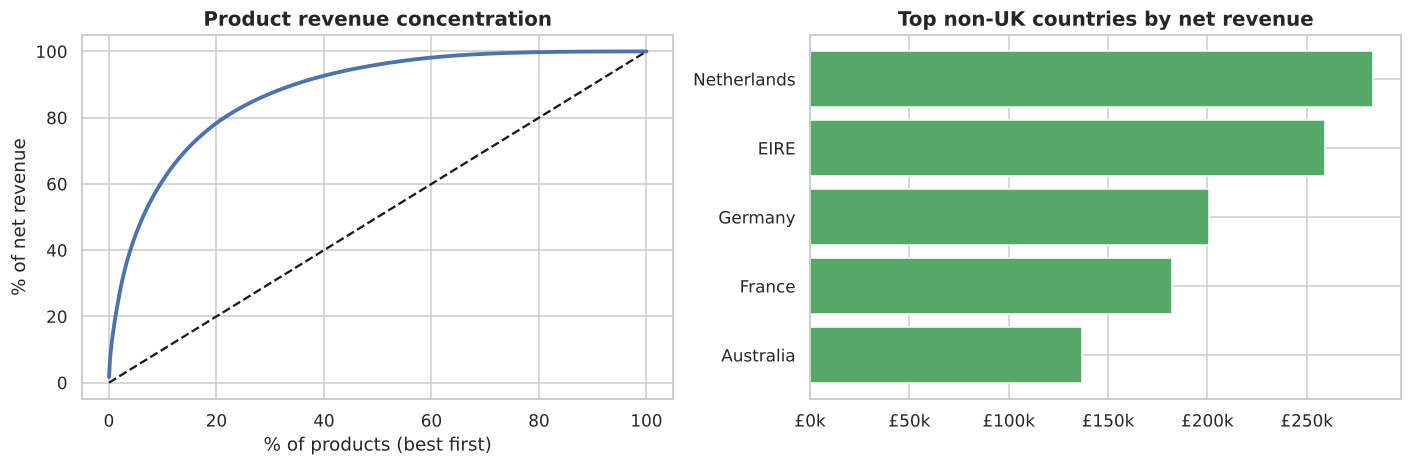

Top 20% of products = 78% of revenue (3,914 products). UK = 85% of revenue.
Non-UK 'customers' are few: Netherlands has 9 customers but GBP 283k revenue -> a handful of wholesale accounts, not a broad market


In [5]:
top_products = run("02_product_pareto"); display(top_products.head(10))
prod = pd.read_sql("SELECT stock_code, SUM(revenue) AS rev FROM transactions GROUP BY stock_code", con).sort_values("rev", ascending=False)
prod["cum"] = prod.rev.cumsum() / prod.rev.sum(); n = len(prod)
top20p = prod.cum.iloc[int(n * .2) - 1]
cty = run("03_country_mix"); display(cty)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ax[0].plot(np.arange(1, n + 1) / n * 100, prod.cum * 100, lw=2.5); ax[0].plot([0, 100], [0, 100], "k--")
ax[0].set_xlabel("% of products (best first)"); ax[0].set_ylabel("% of net revenue"); ax[0].set_title("Product revenue concentration")
c5 = cty.head(6).iloc[1:]; ax[1].barh(c5.country[::-1], c5.net_revenue[::-1], color="#55a868"); ax[1].xaxis.set_major_formatter(gbp_k); ax[1].set_title("Top non-UK countries by net revenue")
plt.tight_layout(); plt.savefig(IMG + "02_products_countries.png"); plt.show()
uk = cty.set_index("country").loc["United Kingdom"]
print(f"Top 20% of products = {top20p:.0%} of revenue ({n:,} products). UK = {uk.share_pct:.0f}% of revenue.")
print(f"Non-UK 'customers' are few: Netherlands has {int(cty.set_index('country').loc['Netherlands','customers'])} customers but GBP {cty.set_index('country').loc['Netherlands','net_revenue']/1e3:,.0f}k revenue -> a handful of wholesale accounts, not a broad market")

## 4. Customer behaviour
### 4.1 Cohort retention (`sql/04_cohort_retention.sql`)
Cohort = month of a customer's first purchase. **Left-censoring warning:** the data starts in Dec 2010, so the "Dec-2010 cohort" is simply everyone who happened to buy then
(including long-standing customers). It is shown but excluded from the averages. Cells that would need December-2011 data (a partial month) are masked.

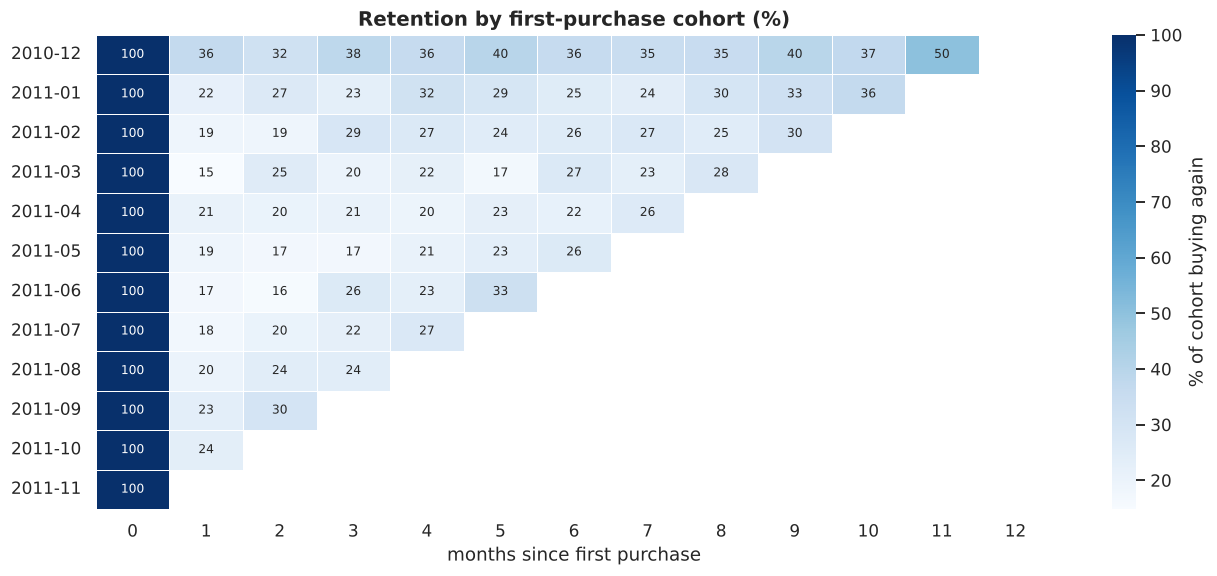

Month 1: 20% of new customers buy again in that month  (weighted over 10 cohorts)
Month 2: 22% of new customers buy again in that month  (weighted over 9 cohorts)
Month 3: 23% of new customers buy again in that month  (weighted over 8 cohorts)
Month 6: 25% of new customers buy again in that month  (weighted over 5 cohorts)
Legacy Dec-2010 group buys in 38% of later months on average (vs ~20%-25% for newly acquired cohorts)


In [6]:
ret = run("04_cohort_retention"); sizes = ret.drop_duplicates("cohort").set_index("cohort").cohort_customers
last_full = mi("2011-11")
heat = ret.pivot(index="cohort", columns="month_number", values="retention_pct").reindex(sizes.index)
mask = pd.DataFrame({k: [mi(c) + k > last_full for c in heat.index] for k in heat.columns}, index=heat.index)
heat = heat.mask(mask).drop(index="2011-12")
plt.figure(figsize=(12, 5.4)); sns.heatmap(heat, annot=True, fmt=".0f", cmap="Blues", linewidths=.4, annot_kws={"size": 8}, cbar_kws={"label": "% of cohort buying again"})
plt.gca().grid(False); plt.title("Retention by first-purchase cohort (%)"); plt.xlabel("months since first purchase"); plt.ylabel("")
plt.tight_layout(); plt.savefig(IMG + "03_cohort_retention.png"); plt.show()

def wret(k):   # size-weighted retention over cohorts (excl. the Dec-2010 legacy cohort) where month k is fully observable
    el = [c for c in sizes.index if c not in ("2010-12", "2011-12") and mi(c) + k <= last_full]
    act = ret[(ret.month_number == k) & ret.cohort.isin(el)].set_index("cohort").active_customers.reindex(el).fillna(0)
    return act.sum() / sizes.loc[el].sum(), len(el)
W = {k: wret(k) for k in (1, 2, 3, 6)}
for k, (v, m) in W.items(): print(f"Month {k}: {v:.0%} of new customers buy again in that month  (weighted over {m} cohorts)")
legacy = heat.loc["2010-12"]; leg = legacy.iloc[1:].mean(); print(f"Legacy Dec-2010 group buys in {leg:.0f}% of later months on average (vs ~{W[1][0]:.0%}-{W[6][0]:.0%} for newly acquired cohorts)")

**Reading:** retention does not decay the way it does in a consumer app. Roughly **one in five new customers buys in any given later month**, and the rate stays flat for a year,
which is typical of wholesale buyers who order when they need stock rather than every month. The legacy Dec-2010 group (long-standing accounts) buys in far more months, so established accounts behave very differently from newly acquired ones.
Two cautions: the legacy group is a survivor-biased sample, and calendar months are mixed into the cohort cells (a cohort's 5th month may land in the autumn peak), so small bumps are seasonality rather than loyalty.

### 4.2 New vs returning revenue, order frequency and concentration
`sql/11_new_vs_returning_revenue.sql`, `sql/05_order_frequency_segments.sql`, `sql/08_customer_deciles.sql`

,order_band,customers,pct_customers,net_revenue,pct_revenue
0,1 order,1505,34.7,536275.0,6.5
1,2 orders,831,19.2,540081.0,6.5
2,3-4 orders,897,20.7,1152247.0,13.9
3,5-8 orders,646,14.9,1482272.0,17.9
4,9+ orders,455,10.5,4558525.0,55.1


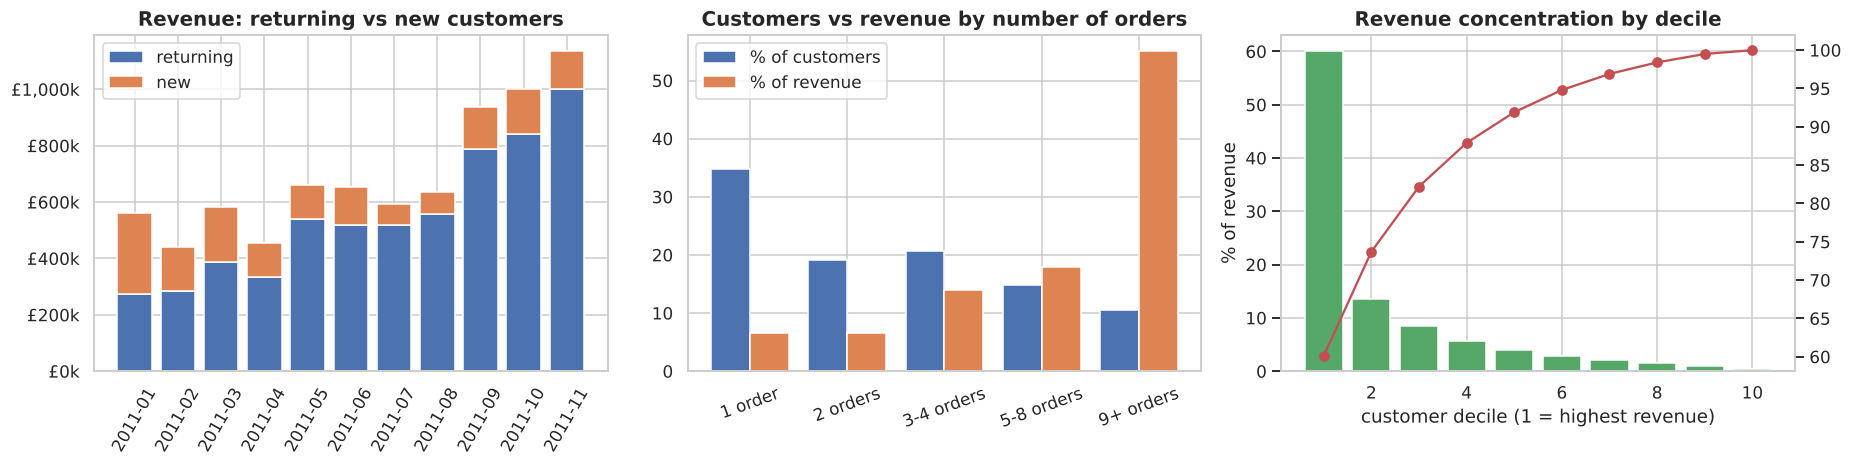

One-time buyers: 35% of customers but only 6.5% of revenue.  9+ orders: 10.5% of customers -> 55% of revenue.
Top 10% of customers = 60% of revenue; top 20% = 74%.


In [7]:
nr = run("11_new_vs_returning_revenue"); nr = nr[(nr.month > "2010-12") & (nr.month < "2011-12")]
fq = run("05_order_frequency_segments"); display(fq)
dec = run("08_customer_deciles")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
ax[0].bar(nr.month, nr.returning_customer_revenue, label="returning", color="#4c72b0"); ax[0].bar(nr.month, nr.new_customer_revenue, bottom=nr.returning_customer_revenue, label="new", color="#dd8452")
ax[0].yaxis.set_major_formatter(gbp_k); ax[0].set_title("Revenue: returning vs new customers"); ax[0].legend(); ax[0].tick_params(axis="x", rotation=60)
x = np.arange(len(fq)); ax[1].bar(x - .2, fq.pct_customers, .4, label="% of customers"); ax[1].bar(x + .2, fq.pct_revenue, .4, label="% of revenue")
ax[1].set_xticks(x); ax[1].set_xticklabels(fq.order_band, rotation=20); ax[1].set_title("Customers vs revenue by number of orders"); ax[1].legend()
ax[2].bar(dec.decile, dec.pct_of_revenue, color="#55a868"); ax2 = ax[2].twinx(); ax2.plot(dec.decile, dec.cumulative_pct, c="#c44e52", marker="o"); ax2.grid(False)
ax[2].set_xlabel("customer decile (1 = highest revenue)"); ax[2].set_ylabel("% of revenue"); ax[2].set_title("Revenue concentration by decile")
plt.tight_layout(); plt.savefig(IMG + "04_customer_behaviour.png"); plt.show()
one = fq.iloc[0]; nine = fq.iloc[-1]
print(f"One-time buyers: {one.pct_customers:.0f}% of customers but only {one.pct_revenue:.1f}% of revenue.  9+ orders: {nine.pct_customers:.1f}% of customers -> {nine.pct_revenue:.0f}% of revenue.")
print(f"Top 10% of customers = {dec.pct_of_revenue.iloc[0]:.0f}% of revenue; top 20% = {dec.cumulative_pct.iloc[1]:.0f}%.")

### 4.3 Repeat-purchase rhythm and loyalty streaks
`sql/06_days_between_orders.sql` (`LAG`), `sql/09_consecutive_month_streaks.sql` (gaps-and-islands).

In [8]:
gp = run("06_days_between_orders"); st = run("09_consecutive_month_streaks"); display(gp); display(st.head(8))
within30 = gp[gp.gap_band.isin(["same day", "1-7 days", "8-14 days", "15-30 days"])].pct_of_repeat_orders.sum()
ge3 = st[st.longest_consecutive_months >= 3].pct_customers.sum()
print(f"{within30:.0f}% of repeat orders happen within 30 days of the previous order; {ge3:.0f}% of customers ever buy in 3+ consecutive months; {int(st.customers.iloc[-1])} customers bought in all {int(st.longest_consecutive_months.iloc[-1])} months.")

,gap_band,repeat_orders,pct_of_repeat_orders,avg_gap_days
0,same day,1724,12.3,0.0
1,1-7 days,2102,14.9,4.2
2,8-14 days,1726,12.3,11.2
3,15-30 days,2728,19.4,22.1
4,31-60 days,2839,20.2,43.3
5,61-90 days,1202,8.5,73.5
6,90+ days,1747,12.4,152.6


,longest_consecutive_months,customers,pct_customers
0,1,2752,63.5
1,2,848,19.6
2,3,305,7.0
3,4,148,3.4
4,5,76,1.8
5,6,46,1.1
6,7,28,0.6
7,8,28,0.6


59% of repeat orders happen within 30 days of the previous order; 17% of customers ever buy in 3+ consecutive months; 44 customers bought in all 13 months.


## 5. RFM segmentation in SQL
`sql/07_rfm_segments.sql` - `NTILE` scores for recency and monetary value, fixed bands for frequency (to avoid arbitrary tie-splitting), CASE rules for segments.

,segment,customers,pct_customers,avg_recency_days,avg_orders,revenue,pct_revenue
0,Champions,814,18.8,11.0,12.4,5356770.0,61.3
1,Loyal,791,18.3,32.0,4.4,1379196.0,15.8
2,Hibernating,1340,30.9,208.0,1.3,678039.0,7.8
3,At Risk,393,9.1,134.0,4.4,653766.0,7.5
4,New / Promising,518,12.0,17.0,1.5,420641.0,4.8
5,Need Attention,478,11.0,52.0,1.4,248817.0,2.8


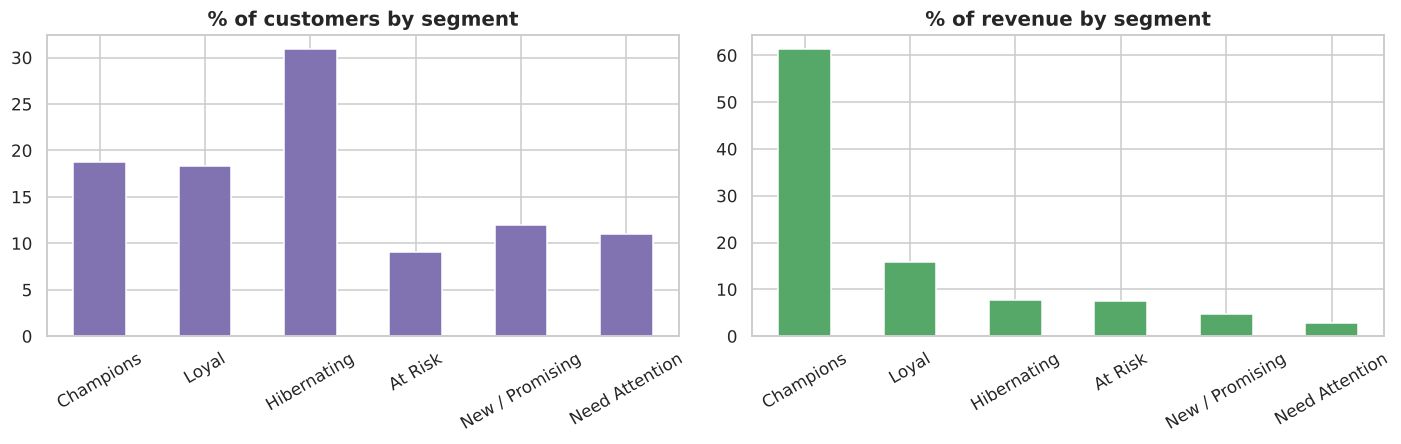

Champions: 19% of customers -> 61% of revenue. At Risk: 393 customers with GBP 654k of past revenue, last bought ~134 days ago.


In [9]:
rfm = run("07_rfm_segments"); display(rfm)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
rfm.set_index("segment").pct_customers.plot.bar(ax=ax[0], color="#8172b2"); ax[0].set_title("% of customers by segment")
rfm.set_index("segment").pct_revenue.plot.bar(ax=ax[1], color="#55a868"); ax[1].set_title("% of revenue by segment")
for a in ax: a.set_xlabel(""); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(IMG + "05_rfm_segments.png"); plt.show()
cl = run("12_rfm_customer_level"); assert cl.segment.value_counts().to_dict() == rfm.set_index("segment").customers.to_dict(), "customer-level RFM must match the segment table"
champ = rfm.set_index("segment").loc["Champions"]; risk = rfm.set_index("segment").loc["At Risk"]
print(f"Champions: {champ.pct_customers:.0f}% of customers -> {champ.pct_revenue:.0f}% of revenue. At Risk: {int(risk.customers)} customers with GBP {risk.revenue/1e3:,.0f}k of past revenue, last bought ~{risk.avg_recency_days:.0f} days ago.")

## 6. Return hotspots
`sql/10_return_hotspots.sql` - products with the highest returned value relative to sales (min. GBP 5,000 sold).

In [10]:
rh = run("10_return_hotspots"); display(rh)
real = rh[rh.return_rate_pct < 90]
print("The first two rows (95-100% 'return rates') are the two mistaken wholesale orders from section 2, not product problems. Real hotspots:")
display(real.head(6))

,stock_code,description,gross_sales,returns_value,return_rate_pct
0,23843,"PAPER CRAFT , LITTLE BIRDIE",168470.0,168470.0,100.0
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,81701.0,77480.0,94.8
2,23113,PANTRY CHOPPING BOARD,5869.0,4803.0,81.8
3,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,18056.0,6591.0,36.5
4,47566B,TEA TIME PARTY BUNTING,11275.0,3693.0,32.8
5,22273,FELTCRAFT DOLL MOLLY,12002.0,3513.0,29.3
6,22191,IVORY DINER WALL CLOCK,11912.0,2654.0,22.3
7,22655,VINTAGE RED KITCHEN CABINET,8125.0,1731.0,21.3
8,48185,DOORMAT FAIRY CAKE,23873.0,4555.0,19.1
9,22838,3 TIER CAKE TIN RED AND CREAM,9765.0,1672.0,17.1


The first two rows (95-100% 'return rates') are the two mistaken wholesale orders from section 2, not product problems. Real hotspots:


,stock_code,description,gross_sales,returns_value,return_rate_pct
2,23113,PANTRY CHOPPING BOARD,5869.0,4803.0,81.8
3,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,18056.0,6591.0,36.5
4,47566B,TEA TIME PARTY BUNTING,11275.0,3693.0,32.8
5,22273,FELTCRAFT DOLL MOLLY,12002.0,3513.0,29.3
6,22191,IVORY DINER WALL CLOCK,11912.0,2654.0,22.3
7,22655,VINTAGE RED KITCHEN CABINET,8125.0,1731.0,21.3


## 7. Predicting next-quarter customer value (out-of-time validation)
**Goal:** if marketing can contact only part of the base, who is worth contacting? We predict each customer's **net revenue in the next 3 months** from their past 6 months.

**Why out-of-time:** a random split lets the model peek at the future (the same customer appears in train and test around the same dates). Here the model is trained on one pair of windows and tested on a **later** pair:

| | Look-back (features) | Next 3 months (target) |
|---|---|---|
| **Train** | 1 Dec 2010 - 31 May 2011 | 1 Jun - 31 Aug 2011 |
| **Test** | 1 Mar 2011 - 31 Aug 2011 | 1 Sep - 30 Nov 2011 |

The test target period is the pre-Christmas peak that the training target period never saw, which is a deliberately tough, realistic check.

In [11]:
tx = pd.read_sql("SELECT invoice_no, invoice_ts, customer_id, stock_code, revenue, is_cancel FROM transactions WHERE customer_id IS NOT NULL", con, parse_dates=["invoice_ts"])
tx["date"] = tx.invoice_ts.dt.normalize(); tx["ym"] = tx.date.dt.to_period("M")
sales, rets = tx[tx.is_cancel == 0], tx[tx.is_cancel == 1]

def build(look_start, cal_end, hold_end):
    ls, ce, he = map(pd.Timestamp, (look_start, cal_end, hold_end))
    s = sales[(sales.date >= ls) & (sales.date <= ce)]; g = s.groupby("customer_id")
    X = pd.DataFrame({"recency_days": (ce - g.date.max()).dt.days, "frequency": g.invoice_no.nunique(), "monetary": g.revenue.sum(),
                      "n_products": g.stock_code.nunique(), "active_months": g.ym.nunique()})
    X["avg_order_value"] = X.monetary / X.frequency
    for d in (30, 90): X[f"spend_last_{d}d"] = s[s.date > ce - pd.Timedelta(days=d)].groupby("customer_id").revenue.sum().reindex(X.index).fillna(0)
    r = rets[(rets.date >= ls) & (rets.date <= ce)].groupby("customer_id").revenue.sum().abs()
    X["return_ratio"] = (r.reindex(X.index).fillna(0) / X.monetary).clip(0, 1)
    h = tx[(tx.date > ce) & (tx.date <= he)]
    y = h.groupby("customer_id").revenue.sum().reindex(X.index).fillna(0)
    buy = h[h.is_cancel == 0].groupby("customer_id").size().reindex(X.index).fillna(0).gt(0).astype(int)
    return X, y, buy
Xtr, ytr, btr = build("2010-12-01", "2011-05-31", "2011-08-31")
Xte, yte, bte = build("2011-03-01", "2011-08-31", "2011-11-30")
feats = list(Xtr.columns)
print(f"train customers {len(Xtr):,} (buy again: {btr.mean():.0%}) | test customers {len(Xte):,} (buy again: {bte.mean():.0%})")
print(f"Average next-quarter revenue per customer: train {ytr.mean():,.0f} vs test {yte.mean():,.0f} (the test quarter is the seasonal peak)")

train customers 2,716 (buy again: 50%) | test customers 2,809 (buy again: 60%)
Average next-quarter revenue per customer: train 558 vs test 844 (the test quarter is the seasonal peak)


In [12]:
# regression on log1p(revenue) - revenue is heavy-tailed; negative net values (returns) clipped at 0 for the log
reg = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=250, l2_regularization=1.0, random_state=0).fit(Xtr[feats], np.log1p(ytr.clip(lower=0)))
pred = np.expm1(reg.predict(Xte[feats])).clip(min=0)
# Model B (pre-specified robustness variant, not chosen after looking at test results): Poisson loss on raw revenue - copes with zeros and heavy tails and predicts means directly
reg_p = HistGradientBoostingRegressor(loss="poisson", max_depth=3, learning_rate=0.05, max_iter=250, l2_regularization=1.0, random_state=0).fit(Xtr[feats], ytr.clip(lower=0))
pred_p = reg_p.predict(Xte[feats]).clip(min=0)
clf = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, l2_regularization=1.0, random_state=0).fit(Xtr[feats], btr)
p_buy = clf.predict_proba(Xte[feats])[:, 1]

def capture(score, y, frac=0.2):   # share of the period's revenue that comes from the top `frac` customers ranked by `score`
    k = int(len(y) * frac); idx = np.argsort(-np.asarray(score), kind="stable")[:k]; yy = y.clip(lower=0).values
    return yy[idx].sum() / yy.sum()
scores = {"Random (expected)": None, "Recency only (most recent first)": -Xte.recency_days, "Frequency only": Xte.frequency, "Past spend": Xte.monetary, "Model A (log revenue)": pred, "Model B (Poisson loss)": pred_p}
rows = []
for n, sc in scores.items():
    rows.append({"ranking": n, "revenue captured by top 20%": 0.2 if sc is None else capture(sc, yte),
                 "Spearman vs actual": np.nan if sc is None else stats.spearmanr(sc, yte).statistic})
rows.append({"ranking": "Oracle (best possible)", "revenue captured by top 20%": capture(yte, yte), "Spearman vs actual": 1.0})
res = pd.DataFrame(rows).set_index("ranking"); display(res.style.format({"revenue captured by top 20%": "{:.1%}", "Spearman vs actual": "{:.3f}"}))
auc = pd.Series({"Recency only": roc_auc_score(bte, -Xte.recency_days), "Past spend": roc_auc_score(bte, Xte.monetary), "Frequency only": roc_auc_score(bte, Xte.frequency), "Buy-again model": roc_auc_score(bte, p_buy)})
print("\nWill the customer buy again next quarter? ROC-AUC:"); print(auc.round(3).to_string())
pred_tr = np.expm1(reg.predict(Xtr[feats])).clip(min=0); k_scale = ytr.sum() / pred_tr.sum()
print(f"\nLevel check (total next-quarter revenue, GBP k): actual {yte.sum()/1e3:,.0f} | Model A raw {pred.sum()/1e3:,.0f} (x{pred.sum()/yte.sum():.2f}) | "
      f"Model A rescaled with a factor learnt on the training period {k_scale*pred.sum()/1e3:,.0f} (x{k_scale*pred.sum()/yte.sum():.2f}) | Model B {pred_p.sum()/1e3:,.0f} (x{pred_p.sum()/yte.sum():.2f})")
print(f"-> part of Model A's gap is retransformation bias from modelling log revenue; the rest is the seasonal peak it never saw (avg revenue per customer {yte.mean():,.0f} vs {ytr.mean():,.0f} in the training quarter). Rankings are unaffected by level errors.")

,revenue captured by top 20%,Spearman vs actual
ranking,,
Random (expected),20.0%,nan
Recency only (most recent first),46.0%,0.319
Frequency only,62.4%,0.467
Past spend,66.3%,0.523
Model A (log revenue),64.9%,0.525
Model B (Poisson loss),65.8%,0.514
Oracle (best possible),79.4%,1.000



Will the customer buy again next quarter? ROC-AUC:
Recency only       0.662
Past spend         0.713
Frequency only     0.710
Buy-again model    0.735

Level check (total next-quarter revenue, GBP k): actual 2,370 | Model A raw 702 (x0.30) | Model A rescaled with a factor learnt on the training period 1,616 (x0.68) | Model B 1,553 (x0.66)
-> part of Model A's gap is retransformation bias from modelling log revenue; the rest is the seasonal peak it never saw (avg revenue per customer 844 vs 558 in the training quarter). Rankings are unaffected by level errors.


,customers,avg_predicted,avg_actual,actual_total,pct_of_actual_revenue
decile,,,,,
1,281,2139.9,4541.5,1276153.7,53.8
2,281,208.8,936.7,263225.2,11.1
3,281,71.3,703.0,197539.3,8.3
4,281,33.8,476.3,133830.2,5.6
5,281,16.8,417.0,117165.7,4.9
6,280,10.0,356.7,99878.9,4.2
7,281,6.9,255.8,71886.7,3.0
8,281,4.4,263.0,73900.8,3.1
9,281,2.9,176.6,49634.3,2.1


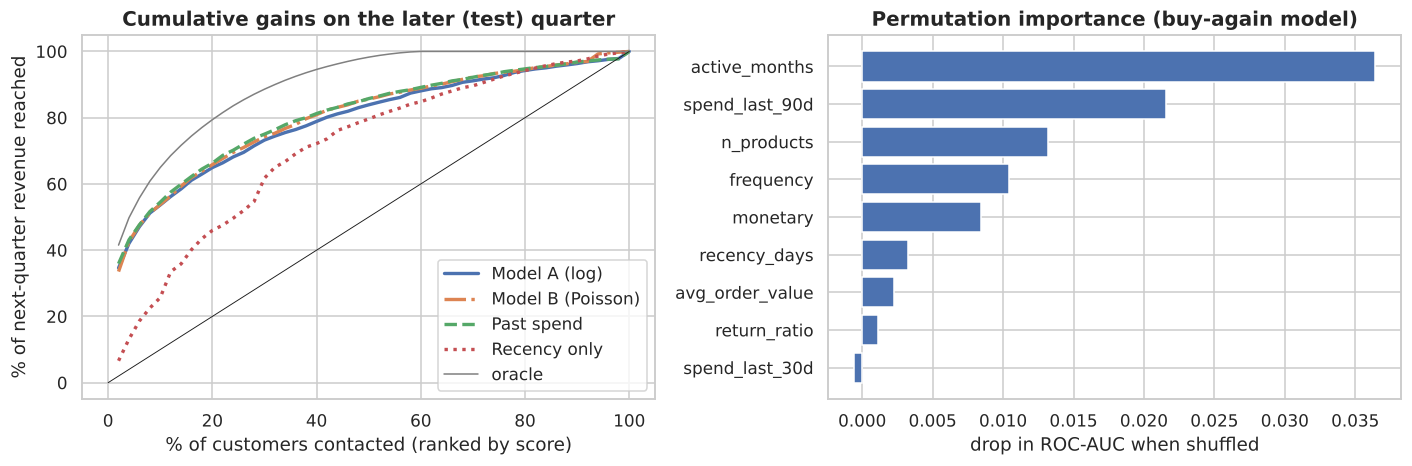

In [13]:
d = pd.DataFrame({"pred": pred, "actual": yte.values}); d["decile"] = pd.qcut(d.pred.rank(method="first", ascending=False), 10, labels=range(1, 11))
dd = d.groupby("decile", observed=True).agg(customers=("actual", "size"), avg_predicted=("pred", "mean"), avg_actual=("actual", "mean"), actual_total=("actual", "sum"))
dd["pct_of_actual_revenue"] = dd.actual_total / dd.actual_total.sum() * 100; display(dd.round(1))
pi = permutation_importance(clf, Xte[feats], bte, scoring="roc_auc", n_repeats=10, random_state=0); imp = pd.Series(pi.importances_mean, index=feats).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ks = np.linspace(0.02, 1, 50)
for n, sc, st_ in [("Model A (log)", pred, "-"), ("Model B (Poisson)", pred_p, "-."), ("Past spend", Xte.monetary, "--"), ("Recency only", -Xte.recency_days, ":")]:
    ax[0].plot(ks * 100, [capture(sc, yte, k) * 100 for k in ks], st_, lw=2.2, label=n)
ax[0].plot(ks * 100, [capture(yte, yte, k) * 100 for k in ks], c="grey", lw=1, label="oracle"); ax[0].plot([0, 100], [0, 100], "k", lw=.6)
ax[0].set_xlabel("% of customers contacted (ranked by score)"); ax[0].set_ylabel("% of next-quarter revenue reached"); ax[0].set_title("Cumulative gains on the later (test) quarter"); ax[0].legend()
ax[1].barh(imp.index, imp.values, color="#4c72b0"); ax[1].set_title("Permutation importance (buy-again model)"); ax[1].set_xlabel("drop in ROC-AUC when shuffled")
plt.tight_layout(); plt.savefig(IMG + "06_customer_value_model.png"); plt.show()

In [14]:
mr = res["revenue captured by top 20%"]
simple = {k: mr[k] for k in ["Recency only (most recent first)", "Frequency only", "Past spend"]}
best_s = max(simple, key=simple.get); best_m = max(["Model A (log revenue)", "Model B (Poisson loss)"], key=lambda k: mr[k]); beats = mr[best_m] > mr[best_s]
edge_txt = ("The best model edges out the best simple rule." if beats else
            "**The models do not beat the best simple rule on this metric**, so for choosing whom to contact a plain RFM-style ranking is just as good.")
auc_txt = f"For the narrower question 'will this customer buy again?' the classifier reaches ROC-AUC {auc['Buy-again model']:.2f} vs {auc['Past spend']:.2f} for past spend."
display(Markdown(f"**How to read this:** the useful number is how much of next quarter's revenue sits in the customers you pick. The best model ({best_m}) reaches **{mr[best_m]:.1%}** with its top 20%, "
                 f"versus **{mr[best_s]:.1%}** for the best simple rule ({best_s}) and {mr['Oracle (best possible)']:.1%} for a perfect oracle. {edge_txt} {auc_txt} "
                 "Finding that a simple rule is enough is a useful result: it tells the business not to over-invest in complex modelling here."))

**How to read this:** the useful number is how much of next quarter's revenue sits in the customers you pick. The best model (Model B (Poisson loss)) reaches **65.8%** with its top 20%, versus **66.3%** for the best simple rule (Past spend) and 79.4% for a perfect oracle. **The models do not beat the best simple rule on this metric**, so for choosing whom to contact a plain RFM-style ranking is just as good. For the narrower question 'will this customer buy again?' the classifier reaches ROC-AUC 0.73 vs 0.71 for past spend. Finding that a simple rule is enough is a useful result: it tells the business not to over-invest in complex modelling here.

## 8. Market-basket analysis (what is bought together)
Rules are mined on **early baskets only** (before 1 Sep 2011) and then re-checked on **later baskets** (1 Sep - 9 Dec 2011), so we see whether the associations are stable or just noise.
* **Support:** how many baskets contain both items. **Confidence:** P(B in basket | A in basket). **Lift:** confidence divided by P(B); lift > 1 means they co-occur more than chance.
* Only the 300 most frequent products and pairs seen in at least 100 early baskets are kept, to avoid tiny-sample lifts.

In [15]:
bk = pd.read_sql("SELECT DISTINCT invoice_no, stock_code, substr(invoice_ts,1,10) AS d FROM transactions WHERE is_cancel = 0", con)
names = pd.read_sql("SELECT stock_code, description, COUNT(*) AS c FROM transactions GROUP BY 1, 2", con).sort_values("c", ascending=False).drop_duplicates("stock_code").set_index("stock_code").description
early, late = bk[bk.d < "2011-09-01"], bk[bk.d >= "2011-09-01"]
P = early.stock_code.value_counts().head(300).index.tolist()
def matrix(df):
    df = df[df.stock_code.isin(P)]; inv, _ = pd.factorize(df.invoice_no); col = df.stock_code.map({p: i for i, p in enumerate(P)}).values
    X = sparse.csr_matrix((np.ones(len(df)), (inv, col)), shape=(inv.max() + 1, len(P))); X.data[:] = 1; return X
def pair_stats(df, min_co):
    X = matrix(df); N = X.shape[0]; co = (X.T @ X).toarray(); n = np.diag(co).copy(); np.fill_diagonal(co, 0)
    i, j = np.where(np.triu(co >= min_co, 1)); out = pd.DataFrame({"a": [P[k] for k in i], "b": [P[k] for k in j], "baskets_both": co[i, j], "n_a": n[i], "n_b": n[j]})
    out["conf_a_to_b"] = out.baskets_both / out.n_a; out["conf_b_to_a"] = out.baskets_both / out.n_b; out["lift"] = out.baskets_both * N / (out.n_a * out.n_b); return out, N
tr, Ntr = pair_stats(early, 100)
top = tr.sort_values("lift", ascending=False).head(50).copy()
te_all, Nte = pair_stats(late, 1); key = lambda d: d.a + "|" + d.b
te_map = te_all.set_index(key(te_all)); top["lift_later"] = key(top).map(te_map.lift); top["baskets_later"] = key(top).map(te_map.baskets_both).fillna(0)
print(f"early baskets: {Ntr:,} | later baskets: {Nte:,} | pairs passing support filter: {len(tr):,}")
show = top.head(12).assign(item_a=lambda d: d.a.map(names).str.title(), item_b=lambda d: d.b.map(names).str.title())[["item_a", "item_b", "baskets_both", "conf_a_to_b", "conf_b_to_a", "lift", "lift_later"]]
display(show.style.format({"conf_a_to_b": "{:.0%}", "conf_b_to_a": "{:.0%}", "lift": "{:.1f}", "lift_later": "{:.1f}"}))

early baskets: 11,196 | later baskets: 6,542 | pairs passing support filter: 1,704


,item_a,item_b,baskets_both,conf_a_to_b,conf_b_to_a,lift,lift_later
1696,Poppy'S Playhouse Kitchen,Poppy'S Playhouse Bedroom,201.000000,73%,73%,29.5,31.1
1660,Small Dolly Mix Design Orange Bowl,Small Marshmallows Pink Bowl,231.000000,69%,80%,26.8,28.0
1694,Blue Happy Birthday Bunting,Pink Happy Birthday Bunting,196.000000,68%,69%,26.7,39.2
1703,Blue Polkadot Cup,Blue Polkadot Bowl,139.000000,55%,57%,25.3,33.3
1699,Red Spot Ceramic Drawer Knob,Blue Spot Ceramic Drawer Knob,152.000000,57%,58%,24.1,31.5
1702,Blue Spot Ceramic Drawer Knob,White Spot Blue Ceramic Drawer Knob,143.000000,54%,56%,23.7,33.8
1676,Feltcraft Cushion Rabbit,Feltcraft Cushion Butterfly,176.000000,56%,65%,23.4,53.3
1693,Watering Can Blue Elephant,Watering Can Pink Bunny,152.000000,53%,60%,23.4,71.1
1662,Scandinavian Paisley Picnic Bag,Pink Vintage Paisley Picnic Bag,223.000000,67%,69%,23.1,38.6
1691,Red Retrospot Cup,Blue Polkadot Cup,150.000000,52%,60%,23.1,39.2


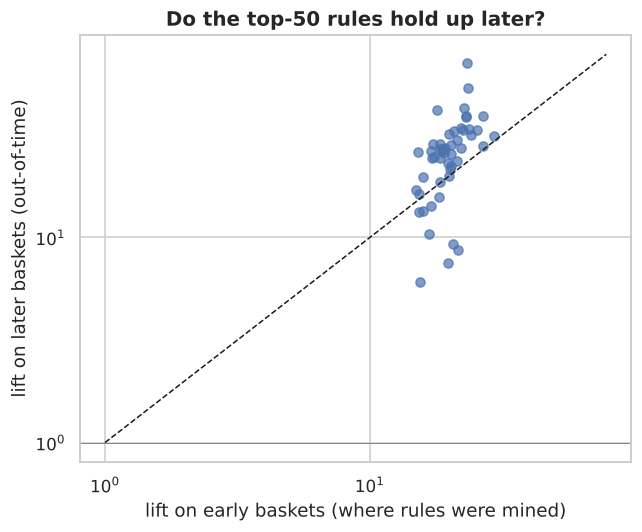

50 of the top-50 rules have enough later baskets to re-check. Median lift: early 19.9 -> later 26.5; 100% still have lift > 2 later; rank correlation 0.63.


In [16]:
ok = top.dropna(subset=["lift_later"]); ok = ok[ok.baskets_later >= 5]
rho = stats.spearmanr(ok.lift, ok.lift_later).statistic
holds = (ok.lift_later > 2).mean()
fig, ax = plt.subplots(figsize=(6, 5)); ax.scatter(ok.lift, ok.lift_later, alpha=.7); lim = [1, max(ok.lift.max(), ok.lift_later.max()) * 1.1]
ax.plot(lim, lim, "k--", lw=1); ax.set_xscale("log"); ax.set_yscale("log"); ax.axhline(1, c="grey", lw=.6)
ax.set_xlabel("lift on early baskets (where rules were mined)"); ax.set_ylabel("lift on later baskets (out-of-time)"); ax.set_title("Do the top-50 rules hold up later?")
plt.tight_layout(); plt.savefig(IMG + "07_basket_rules_stability.png"); plt.show()
print(f"{len(ok)} of the top-50 rules have enough later baskets to re-check. Median lift: early {ok.lift.median():.1f} -> later {ok.lift_later.median():.1f}; "
      f"{holds:.0%} still have lift > 2 later; rank correlation {rho:.2f}.")

**Reading:** in the top-12 table every pair is a *sibling*: the same item in another colour or design, or matching pieces of one range (kitchen + bedroom playhouse, paper plates + cups).
Customers buy sets rather than single items, which points to **bundles, variant packs and merchandising** rather than clever cross-category recommendations.
The associations are stable out-of-time (scatter above): the re-checked rules keep high lift on the later baskets, if anything higher, probably because Q4 gift-set buying makes baskets more set-like.

## 9. Power BI-ready export
A small **star schema** is written to `/powerbi/data` so the same story can be built as an interactive dashboard (see `powerbi/DASHBOARD_SPEC.md` for the page layout, relationships and DAX measures).

In [17]:
import os; OUT = "../powerbi/data/"; os.makedirs(OUT, exist_ok=True)
dates = pd.date_range("2010-12-01", "2011-12-31"); dim_date = pd.DataFrame({"date": dates, "year": dates.year, "month_num": dates.month, "month_name": dates.strftime("%b"),
        "year_month": dates.strftime("%Y-%m"), "weekday": dates.strftime("%a"), "is_partial_month": (dates >= "2011-12-10").astype(int)})
dim_product = names.rename_axis("stock_code").reset_index().rename(columns={"description": "product"})
fact_inv = pd.read_sql("""SELECT invoice_no, substr(MIN(invoice_ts),1,10) AS invoice_date, customer_id, country, MAX(is_cancel) AS is_cancel,
                           COUNT(*) AS lines, SUM(quantity) AS units, ROUND(SUM(revenue),2) AS revenue FROM transactions GROUP BY invoice_no""", con)
fact_pm = pd.read_sql("""SELECT strftime('%Y-%m', invoice_ts) || '-01' AS month_start, stock_code,
                          SUM(CASE WHEN is_cancel=0 THEN quantity ELSE 0 END) AS units_sold,
                          ROUND(SUM(CASE WHEN is_cancel=0 THEN revenue ELSE 0 END),2) AS gross_sales,
                          ROUND(-SUM(CASE WHEN is_cancel=1 THEN revenue ELSE 0 END),2) AS returns_value FROM transactions GROUP BY 1, 2""", con)
cinfo = pd.read_sql("""SELECT customer_id, MAX(country) AS country, substr(MIN(CASE WHEN is_cancel=0 THEN invoice_ts END),1,10) AS first_order_date,
                          substr(MAX(CASE WHEN is_cancel=0 THEN invoice_ts END),1,10) AS last_order_date, ROUND(SUM(revenue),2) AS net_revenue
                          FROM transactions WHERE customer_id IS NOT NULL GROUP BY customer_id""", con)
dim_customer = cinfo.merge(cl.rename(columns={"frequency": "orders", "monetary": "gross_sales"}), on="customer_id", how="left")
for n, d in {"dim_date": dim_date, "dim_product": dim_product, "dim_customer": dim_customer, "fact_invoice": fact_inv, "fact_product_month": fact_pm}.items():
    d.to_csv(OUT + n + ".csv", index=False); print(f"{n:<20s} {len(d):>7,} rows  {os.path.getsize(OUT + n + '.csv')/1e6:5.1f} MB")

dim_date                 396 rows    0.0 MB
dim_product            3,914 rows    0.1 MB
dim_customer           4,362 rows    0.4 MB
fact_invoice          23,195 rows    1.3 MB
fact_product_month    34,088 rows    1.0 MB


## 10. Findings, recommendations and limitations

In [18]:
mist = pd.read_sql("SELECT SUM(revenue) AS r FROM transactions WHERE invoice_no IN ('541431', '581483')", con).r[0]
verdict = "The models do not beat ranking by past spend, so simple RFM is enough for targeting." if not beats else "The best model edges out ranking by past spend."
display(Markdown(f'''
| # | Finding | Evidence |
|---|---|---|
| 1 | **Strongly seasonal, Q4-loaded** | Sep-Nov 2011 = {q4:.0%} of the 12 full months' net revenue |
| 2 | **A tiny core carries the business** | Top 10% of customers = {dec.pct_of_revenue.iloc[0]:.0f}% of revenue; 9+ order customers = {nine.pct_customers:.1f}% of customers but {nine.pct_revenue:.0f}% of revenue; Champions {champ.pct_customers:.0f}% of customers -> {champ.pct_revenue:.0f}% of revenue |
| 3 | **Retention is flat and low for new accounts** | About {W[1][0]:.0%} of a new cohort buys in month 1 and {W[6][0]:.0%} in month 6; long-standing legacy accounts buy in ~{leg:.0f}% of months |
| 4 | **Most customers are one-time buyers** | {one.pct_customers:.0f}% of customers placed one order = {one.pct_revenue:.1f}% of revenue |
| 5 | **Value model vs simple rules (out-of-time)** | Top 20% of customers reach: Model A {mr["Model A (log revenue)"]:.0%}, Model B {mr["Model B (Poisson loss)"]:.0%}, past spend {mr["Past spend"]:.0%}, recency {mr["Recency only (most recent first)"]:.0%} of next-quarter revenue (oracle {mr["Oracle (best possible)"]:.0%}). {verdict} Buy-again ROC-AUC {auc["Buy-again model"]:.2f} vs {auc["Past spend"]:.2f} for past spend |
| 6 | **Co-purchases are sibling products** | Top pairs are variants or matching pieces of one range; {holds:.0%} of the re-checked top-50 rules keep lift > 2 on later baskets (median lift {ok.lift.median():.0f} early, {ok.lift_later.median():.0f} later) |
| 7 | **International is a few big accounts** | UK {uk.share_pct:.0f}% of revenue; non-UK markets have few customers with very large orders |
| 8 | **Data quality changes the story** | Two mistaken wholesale orders (GBP 77k and 168k) were reversed within 16 and 12 minutes. Dropping cancellations would overstate revenue by GBP {mist/1e3:,.0f}k ({mist/kpi.net_revenue.sum():.1%}) |

**Recommendations**
1. Protect the **Champions / Loyal** accounts (named account management, early access to new lines) - they are most of the revenue.
2. Build the **Q4 plan** from September: stock, staffing and campaigns.
3. Trigger a **second-order incentive** within 30 days of a first purchase (most repeat orders happen within 30 days).
4. Run a **win-back** campaign on "At Risk" customers; rank them by past spend (a simple ranking was as good as the models).
5. Merchandise **bundles/variant packs** from the stable basket rules; test them with an A/B experiment.
6. For choosing whom to contact, start with a simple past-spend/RFM ranking; only add the model if it later proves a measurable edge.

**Limitations:** one year of data (no year-over-year comparison, and the model never saw a previous Q4); wholesale accounts dominate, so findings may not transfer to consumers;
guest checkouts (about a quarter of lines) are excluded from customer analyses; the value model is trained on a single earlier window; basket rules show association, not causation;
the Dec-2010 cohort is left-censored.
'''))


| # | Finding | Evidence |
|---|---|---|
| 1 | **Strongly seasonal, Q4-loaded** | Sep-Nov 2011 = 38% of the 12 full months' net revenue |
| 2 | **A tiny core carries the business** | Top 10% of customers = 60% of revenue; 9+ order customers = 10.5% of customers but 55% of revenue; Champions 19% of customers -> 61% of revenue |
| 3 | **Retention is flat and low for new accounts** | About 20% of a new cohort buys in month 1 and 25% in month 6; long-standing legacy accounts buy in ~38% of months |
| 4 | **Most customers are one-time buyers** | 35% of customers placed one order = 6.5% of revenue |
| 5 | **Value model vs simple rules (out-of-time)** | Top 20% of customers reach: Model A 65%, Model B 66%, past spend 66%, recency 46% of next-quarter revenue (oracle 79%). The models do not beat ranking by past spend, so simple RFM is enough for targeting. Buy-again ROC-AUC 0.73 vs 0.71 for past spend |
| 6 | **Co-purchases are sibling products** | Top pairs are variants or matching pieces of one range; 100% of the re-checked top-50 rules keep lift > 2 on later baskets (median lift 20 early, 26 later) |
| 7 | **International is a few big accounts** | UK 85% of revenue; non-UK markets have few customers with very large orders |
| 8 | **Data quality changes the story** | Two mistaken wholesale orders (GBP 77k and 168k) were reversed within 16 and 12 minutes. Dropping cancellations would overstate revenue by GBP 246k (2.5%) |

**Recommendations**
1. Protect the **Champions / Loyal** accounts (named account management, early access to new lines) - they are most of the revenue.
2. Build the **Q4 plan** from September: stock, staffing and campaigns.
3. Trigger a **second-order incentive** within 30 days of a first purchase (most repeat orders happen within 30 days).
4. Run a **win-back** campaign on "At Risk" customers; rank them by past spend (a simple ranking was as good as the models).
5. Merchandise **bundles/variant packs** from the stable basket rules; test them with an A/B experiment.
6. For choosing whom to contact, start with a simple past-spend/RFM ranking; only add the model if it later proves a measurable edge.

**Limitations:** one year of data (no year-over-year comparison, and the model never saw a previous Q4); wholesale accounts dominate, so findings may not transfer to consumers;
guest checkouts (about a quarter of lines) are excluded from customer analyses; the value model is trained on a single earlier window; basket rules show association, not causation;
the Dec-2010 cohort is left-censored.
